In [9]:
import numpy as np
import pandas as pd
from pathlib import Path
from arch import arch_model
from sklearn.model_selection import TimeSeriesSplit
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent
OUT_PATH     = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

In [142]:
df_train = pd.read_parquet(OUT_PATH / "brent_train.parquet")

y  = df_train["log_returns"].values.astype("float64")
rs = df_train["rs_daily"].values.astype("float64")

print(f"Train: {len(y)} obs ({df_train.index[0].date()} → {df_train.index[-1].date()})")

Train: 2171 obs (2014-01-03 → 2022-11-03)


In [117]:
"""
Volatility model selection module.

Supports ARCH, GARCH, GJR-GARCH and EGARCH via the `arch` library.
All hyperparameter search uses time-series cross-validation (TSCV).

NOTATION
--------
Classic econometric notation is used in the public API:
    ARCH(q)         : q lags of squared innovations
    GARCH(p, q)     : p lagged variances + q lagged squared innovations
    GJR-GARCH(p, q) : GARCH + asymmetric term (threshold)
    EGARCH(p, q)    : GARCH in log-variance with asymmetric term

The `arch` library uses the OPPOSITE convention for (p, q). This module
translates internally, so the public API is always in classic notation.

ESTIMATION VS PREDICTION
------------------------
Parameters are estimated by standard MLE on the return series (in-sample).
Parameters are then FROZEN and used for out-of-sample prediction. No
re-estimation occurs during the test block.

HERMETIC VALIDATION
-------------------
Each validation fold is treated as a hermetic block. Lags for the first
predictions are NOT taken from the training set. The first `burn_in`
points of each fold are discarded, where
    burn_in = q           for ARCH(q)
    burn_in = max(p, q)   for GARCH, GJR-GARCH, EGARCH
This guarantees that no information from training leaks into validation.

STATE ANCHORING
---------------
The conditional variance sigma^2_t is latent (not observed). In the
standard GARCH recursion, the lagged state sigma^2_{t-j} is a previous
prediction, which propagates the prediction error with weight beta_j.
With beta close to 1, this error accumulates and (for EGARCH) explodes.

To break this propagation, the lagged state sigma^2_{t-j} is replaced by
the observed realized volatility RS_{t-j} (Rogers-Satchell), which is an
unbiased estimator: E[RS_t | F_{t-1}] = sigma^2_t. This substitution
preserves the expectation of the recursion, anchors the state to observed
data, and eliminates error accumulation.

This anchoring is applied ONLY to the GARCH family. ML/DL models do not
propagate a latent state with a fixed coefficient and do not require it.

METRIC INDEPENDENCE AND AGGREGATION
-----------------------------------
Each metric is computed independently per fold. If one metric produces
inf or NaN in a fold, the other metrics are unaffected.

Aggregation of per-fold values is controlled by the `aggregate` argument:
    aggregate="robust"  : median and IQR
    aggregate="trimmed" : 20% trimmed mean and IQR
    aggregate="classic" : mean and std

Infinite values are replaced by a large finite cap before aggregating,
so that robust aggregators (median, trimmed, IQR) are unaffected while
the count of exploded folds (n_exploded) is preserved. The mean and std
are reported for diagnostics only; they are NOT robust when n_exploded>0.

HORIZON
-------
h = 1 (default): rolling one-step-ahead.
h > 1          : first step anchored to RS, subsequent steps propagate.
"""
import numpy as np
import pandas as pd
import warnings
from arch import arch_model
from sklearn.model_selection import TimeSeriesSplit
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")


_MODEL_REGISTRY = {
    "ARCH":      {"vol": "ARCH",   "asym": False},
    "GARCH":     {"vol": "GARCH",  "asym": False},
    "GJR-GARCH": {"vol": "GARCH",  "asym": True},
    "EGARCH":    {"vol": "EGARCH", "asym": True},
}

_O_ASYM = 1

_AGG_MODES = ("robust", "trimmed", "classic")

_INF_CAP = 1e6          # value used to replace inf before aggregating
_TRIM_FRAC = 0.2        # trimmed mean fraction (20%)


# ============================================================
# METRIC REGISTRY
# ============================================================
def _qlike(y_true, y_pred, eps=1e-8):
    ratio = (y_true + eps) / (y_pred + eps)
    return np.mean(ratio - np.log(ratio) - 1)


def _mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def _rmse(y_true, y_pred):
    return np.sqrt(_mse(y_true, y_pred))


def _mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


METRIC_REGISTRY = {
    "qlike": _qlike,
    "mse":   _mse,
    "rmse":  _rmse,
    "mae":   _mae,
}


def _resolve_metrics(metrics):
    if metrics is None:
        return {"qlike": METRIC_REGISTRY["qlike"]}
    if metrics == "all":
        return dict(METRIC_REGISTRY)
    if isinstance(metrics, str):
        metrics = [metrics]
    resolved = {}
    for name in metrics:
        if name not in METRIC_REGISTRY:
            raise ValueError(f"Métrica desconocida: {name}. Disponibles: {list(METRIC_REGISTRY)}")
        resolved[name] = METRIC_REGISTRY[name]
    return resolved


# ============================================================
# AGGREGATION
# ============================================================
def _trimmed_mean(arr, trim=_TRIM_FRAC):
    """Trimmed mean of finite values. Falls back to median if trim too aggressive."""
    finite = arr[np.isfinite(arr)]
    n = len(finite)
    if n == 0:
        return np.nan
    k = int(np.floor(n * trim))
    if 2 * k >= n:
        return float(np.median(finite))
    sorted_arr = np.sort(finite)
    return float(np.mean(sorted_arr[k:n-k]))


def _aggregate(values, cap_value=_INF_CAP):
    """
    Aggregate per-fold metric values into summary statistics.

    inf and -inf are replaced by a large finite cap before aggregating,
    so robust aggregators (median, trimmed, IQR) are unaffected while
    preserving the information that at least one fold exploded.

    Returns
    -------
    dict with keys:
        mean, std, median, q1, q3, iqr, trimmed, n_valid, n_exploded
    """
    arr = np.asarray(values, dtype=float)

    # Count exploded folds BEFORE capping
    n_exploded = int(np.sum(np.isinf(arr)))

    # Replace inf with a large finite cap
    arr_capped = np.where(np.isinf(arr), cap_value, arr)
    arr_capped = np.where(np.isnan(arr_capped), np.nan, arr_capped)

    n_valid = int(np.sum(~np.isnan(arr_capped)))
    if n_valid == 0:
        return {
            "mean": np.nan, "std": np.nan, "median": np.nan,
            "q1": np.nan, "q3": np.nan, "iqr": np.nan,
            "trimmed": np.nan, "n_valid": 0, "n_exploded": n_exploded,
        }

    finite = arr_capped[~np.isnan(arr_capped)]
    q1 = float(np.percentile(finite, 25))
    q3 = float(np.percentile(finite, 75))

    return {
        "mean":       float(np.mean(arr_capped)),
        "std":        float(np.std(arr_capped)),
        "median":     float(np.median(finite)),
        "q1":         q1,
        "q3":         q3,
        "iqr":        q3 - q1,
        "trimmed":    _trimmed_mean(arr_capped),
        "n_valid":    n_valid,
        "n_exploded": n_exploded,
    }


def _resolve_agg_columns(metric, aggregate):
    """Return (value_col, spread_col) for a given metric and aggregate mode."""
    if aggregate == "robust":
        return f"{metric}_median", f"{metric}_iqr"
    if aggregate == "trimmed":
        return f"{metric}_trimmed", f"{metric}_iqr"
    if aggregate == "classic":
        return f"{metric}_mean", f"{metric}_std"
    raise ValueError(f"aggregate debe ser uno de {_AGG_MODES}, no '{aggregate}'")


# ============================================================
# OPTIMIZER DEFAULTS
# ============================================================
_DEFAULT_OPTIM_OPTS = {
    "maxiter": 500,
    "ftol":    1e-5,
    "gtol":    1e-5,
}


def _merge_optim_opts(optim_opts):
    opts = dict(_DEFAULT_OPTIM_OPTS)
    if optim_opts:
        opts.update(optim_opts)
    return opts


# ============================================================
# PRIVATE: burn-in helper
# ============================================================
def _burn_in(family, order):
    if family == "ARCH":
        return order["q"]
    p, q = order["p"], order["q"]
    return max(p, q)


# ============================================================
# PRIVATE: model building
# ============================================================
def _build_model(y, family, order, dist):
    cfg = _MODEL_REGISTRY[family]
    kwargs = {"vol": cfg["vol"], "dist": dist, "mean": "Zero"}

    if family == "ARCH":
        kwargs["p"] = order["q"]
        kwargs["q"] = 0
    else:
        kwargs["p"] = order["q"]
        kwargs["q"] = order["p"]
        if cfg["asym"]:
            kwargs["o"] = _O_ASYM

    return arch_model(y, **kwargs)


def _fit(y, family, order, dist, optim_opts=None):
    model = _build_model(y, family, order, dist)
    opts  = _merge_optim_opts(optim_opts)
    res = model.fit(
        disp="off",
        show_warning=False,
        options=opts,
    )
    if not np.all(np.isfinite(res.params.values)):
        raise RuntimeError("parámetros no finitos")
    return res


# ============================================================
# PRIVATE: rolling forecasts (hermetic, RS-anchored)
# ============================================================
def _forecast_arch(y_full, rs_full, order, res, t0, t1, h=1):
    q = order["q"]
    w = _burn_in("ARCH", order)
    omega  = res.params["omega"]
    alphas = np.array([res.params[f"alpha[{i}]"] for i in range(1, q + 1)])
    eps_sq = y_full ** 2

    sigmas = []
    for t in range(t0 + w, t1 - h + 1):
        s2_h1 = omega + np.sum(alphas * eps_sq[t - q:t][::-1])
        s2 = s2_h1
        for _ in range(1, h):
            s2 = omega + np.sum(alphas) * s2
        sigmas.append(s2)

    return np.array(sigmas)


def _forecast_garch(y_full, rs_full, order, res, t0, t1, h=1):
    p, q = order["p"], order["q"]
    w = _burn_in("GARCH", order)
    omega  = res.params["omega"]
    alphas = np.array([res.params[f"alpha[{i}]"] for i in range(1, q + 1)])
    betas  = np.array([res.params[f"beta[{j}]"]  for j in range(1, p + 1)])

    eps_sq = y_full ** 2

    sigmas = []
    for t in range(t0 + w, t1 - h + 1):
        arch_term  = np.sum(alphas * eps_sq[t - q:t][::-1])
        garch_term = np.sum(betas  * rs_full[t - p:t][::-1])
        s2_h1 = omega + arch_term + garch_term

        s2 = s2_h1
        for _ in range(1, h):
            s2 = omega + (np.sum(alphas) + np.sum(betas)) * s2

        sigmas.append(s2)

    return np.array(sigmas)


def _forecast_gjr(y_full, rs_full, order, res, t0, t1, h=1):
    p, q = order["p"], order["q"]
    o = _O_ASYM
    w = _burn_in("GJR-GARCH", order)
    omega  = res.params["omega"]
    alphas = np.array([res.params[f"alpha[{i}]"] for i in range(1, q + 1)])
    gammas = np.array([res.params[f"gamma[{i}]"] for i in range(1, o + 1)])
    betas  = np.array([res.params[f"beta[{j}]"]  for j in range(1, p + 1)])

    eps = y_full

    sigmas = []
    for t in range(t0 + w, t1 - h + 1):
        eps_lag    = eps[t - q:t][::-1]
        eps_sq_lag = eps_lag ** 2
        indicator  = (eps_lag < 0).astype(float)

        arch_term  = np.sum(alphas * eps_sq_lag)
        asym_term  = np.sum(gammas * indicator[:o] * eps_sq_lag[:o])
        garch_term = np.sum(betas  * rs_full[t - p:t][::-1])
        s2_h1 = omega + arch_term + asym_term + garch_term

        s2 = s2_h1
        for _ in range(1, h):
            s2 = omega + (np.sum(alphas) + 0.5 * np.sum(gammas) + np.sum(betas)) * s2

        sigmas.append(s2)

    return np.array(sigmas)


def _forecast_egarch(y_full, rs_full, order, res, t0, t1, h=1):
    p, q = order["p"], order["q"]
    o = _O_ASYM
    w = _burn_in("EGARCH", order)
    omega  = res.params["omega"]
    alphas = np.array([res.params[f"alpha[{i}]"] for i in range(1, q + 1)])
    gammas = np.array([res.params[f"gamma[{i}]"] for i in range(1, o + 1)])
    betas  = np.array([res.params[f"beta[{j}]"]  for j in range(1, p + 1)])

    sigma_train = np.asarray(res.conditional_volatility)
    z_train = y_full[:t0] / sigma_train
    E_abs_z = np.nanmean(np.abs(z_train))

    eps = y_full
    log_rs_full = np.log(rs_full + 1e-12)

    sigmas = []
    for t in range(t0 + w, t1 - h + 1):
        eps_lag   = eps[t - q:t][::-1]
        sigma_lag = np.sqrt(rs_full[t - q:t][::-1])
        z_lag     = eps_lag / (sigma_lag + 1e-12)

        mag_term  = np.sum(alphas * (np.abs(z_lag) - E_abs_z))
        asym_term = np.sum(gammas * z_lag[:o])

        log_state_lag = log_rs_full[t - p:t][::-1]
        log_s2 = omega + mag_term + asym_term + np.sum(betas * log_state_lag)

        s2_h1 = np.exp(log_s2)
        log_s2_h1 = log_s2

        log_s2 = log_s2_h1
        for _ in range(1, h):
            log_s2 = omega + np.sum(betas) * log_s2

        s2 = np.exp(log_s2)

        sigmas.append(s2)

    return np.array(sigmas)


_FORECASTERS = {
    "ARCH":      _forecast_arch,
    "GARCH":     _forecast_garch,
    "GJR-GARCH": _forecast_gjr,
    "EGARCH":    _forecast_egarch,
}


# ============================================================
# PUBLIC: TSCV evaluation of one configuration
# ============================================================
def evaluate_tscv(
    y, rs, family, order, dist,
    h=1,
    n_splits=5,
    metrics="qlike",
    optim_opts=None,
):
    if not isinstance(h, int) or h < 1:
        raise ValueError("h debe ser un entero positivo")

    metric_fns = _resolve_metrics(metrics)
    forecaster = _FORECASTERS[family]
    w = _burn_in(family, order)

    tscv = TimeSeriesSplit(n_splits=n_splits)
    per_fold = {name: [] for name in metric_fns}
    n_failed = 0

    for train_idx, val_idx in tscv.split(y):
        t0 = train_idx[-1] + 1
        t1 = val_idx[-1] + 1
        try:
            res = _fit(y[:t0], family, order, dist, optim_opts=optim_opts)
            sigmas = forecaster(y, rs, order, res, t0, t1, h=h)
            rs_target = rs[t0 + w + h - 1: t1]

            for name, fn in metric_fns.items():
                per_fold[name].append(fn(rs_target, sigmas))

        except Exception:
            n_failed += 1
            for name in metric_fns:
                per_fold[name].append(np.nan)

    out = {}
    for name in metric_fns:
        out[name] = _aggregate(per_fold[name])
    out["n_failed"] = n_failed
    return out


# ============================================================
# PUBLIC: grid builders
# ============================================================
def build_grid(family, p_max=3, q_max=3):
    if family == "ARCH":
        return [{"q": q} for q in range(1, q_max + 1)]
    return [{"p": p, "q": q}
            for p in range(1, p_max + 1)
            for q in range(1, q_max + 1)]


# ============================================================
# PUBLIC: grid search — in-sample (AIC/BIC/HQIC)
# ============================================================
def grid_search_insample(y, family, grid, dists, optim_opts=None, progress=False):
    T = len(y)
    rows = []
    iterable = tqdm(
        [(order, dist) for order in grid for dist in dists],
        desc=f"{family} in-sample",
        disable=not progress,
    )
    for order, dist in iterable:
        try:
            res = _fit(y, family, order, dist, optim_opts=optim_opts)
            loglik = res.loglikelihood
            k = len(res.params)
            rows.append({
                "model": family, **order, "dist": dist,
                "loglik": loglik, "k": k,
                "AIC":  -2 * loglik + 2 * k,
                "BIC":  -2 * loglik + k * np.log(T),
                "HQIC": -2 * loglik + 2 * k * np.log(np.log(T)),
            })
        except Exception:
            rows.append({
                "model": family, **order, "dist": dist,
                "loglik": np.nan, "k": np.nan,
                "AIC": np.nan, "BIC": np.nan, "HQIC": np.nan,
            })
    return pd.DataFrame(rows)


# ============================================================
# PUBLIC: grid search — predictive (TSCV)
# ============================================================
def grid_search_predictive(
    y, rs, family, grid, dists,
    h=1,
    n_splits=5,
    metrics="qlike",
    optim_opts=None,
    progress=False,
):
    metric_fns = _resolve_metrics(metrics)
    rows = []
    iterable = tqdm(
        [(order, dist) for order in grid for dist in dists],
        desc=f"{family} TSCV h={h}",
        disable=not progress,
    )
    for order, dist in iterable:
        scores = evaluate_tscv(
            y, rs, family, order, dist,
            h=h,
            n_splits=n_splits,
            metrics=metrics,
            optim_opts=optim_opts,
        )
        row = {"model": family, **order, "dist": dist}
        for name in metric_fns:
            row[f"{name}_mean"]       = scores[name]["mean"]
            row[f"{name}_std"]        = scores[name]["std"]
            row[f"{name}_median"]     = scores[name]["median"]
            row[f"{name}_iqr"]        = scores[name]["iqr"]
            row[f"{name}_trimmed"]    = scores[name]["trimmed"]
            row[f"{name}_n"]          = scores[name]["n_valid"]
            row[f"{name}_n_exploded"] = scores[name]["n_exploded"]
        row["n_failed"] = scores["n_failed"]
        rows.append(pd.Series(row))
    return pd.DataFrame(rows)


# ============================================================
# PUBLIC: select best row
# ============================================================
def select_best(df, metric="qlike", aggregate="robust",
                max_failed=None, max_exploded=None, require_full_n=True):
    """
    Select the best row by `metric` under the chosen `aggregate` mode.

    Parameters
    ----------
    df : DataFrame
        Output of grid_search_predictive.
    metric : str
        Metric name (e.g. "qlike", "mse", "rmse", "mae").
    aggregate : str
        "robust"  -> use median
        "trimmed" -> use trimmed mean (20%)
        "classic" -> use mean
    max_failed : int or None
        Discard rows with n_failed > max_failed.
    max_exploded : int or None
        Discard rows with <metric>_n_exploded > max_exploded.
    require_full_n : bool
        If True, restrict to rows where the metric's n_valid equals
        the maximum n_valid across rows.
    """
    value_col, _ = _resolve_agg_columns(metric, aggregate)
    if value_col not in df.columns:
        raise ValueError(f"Columna '{value_col}' no encontrada en el DataFrame.")

    df_clean = df.dropna(subset=[value_col]).copy()

    if max_failed is not None and "n_failed" in df_clean.columns:
        df_clean = df_clean[df_clean["n_failed"] <= max_failed]

    exploded_col = f"{metric}_n_exploded"
    if max_exploded is not None and exploded_col in df_clean.columns:
        df_clean = df_clean[df_clean[exploded_col] <= max_exploded]

    n_col = f"{metric}_n"
    if require_full_n and n_col in df_clean.columns:
        max_n = df_clean[n_col].max()
        df_clean = df_clean[df_clean[n_col] == max_n]

    if df_clean.empty:
        return None
    return df_clean.loc[df_clean[value_col].idxmin()]


# ============================================================
# PUBLIC: format comparison table (numeric, not string)
# ============================================================
def format_table(
    df,
    aggregate="robust",
    metrics=("qlike", "mse", "rmse", "mae"),
    sort_by=None,
    ascending=True,
    include_n=True,
    include_exploded=True,
    rename=None,
):
    """
    Return a comparison table with separate numeric columns for the
    center and spread of each metric.

    Parameters
    ----------
    df : DataFrame
        Output of grid_search_predictive.
    aggregate : str
        "robust"   -> center = median,         spread = IQR
        "trimmed"  -> center = trimmed (20%),  spread = IQR
        "classic"  -> center = mean,           spread = std
    metrics : tuple of str
        Metrics to include (must exist in df).
    sort_by : str or None
        Metric name to sort by. Defaults to the first metric in `metrics`.
    ascending : bool
        Sort ascending (lower is better for losses).
    include_n : bool
        If True, include the n_valid column of the primary metric and n_failed.
    include_exploded : bool
        If True, include the n_exploded column of the primary metric.
    rename : dict or None
        Optional mapping to rename output columns.

    Returns
    -------
    DataFrame with columns:
        [model, p, q, dist,
         <metric1>_center, <metric1>_spread,
         <metric2>_center, <metric2>_spread,
         ...,
         <sort_by>_n, <sort_by>_n_exploded, n_failed]
    """
    if aggregate not in _AGG_MODES:
        raise ValueError(f"aggregate debe ser uno de {_AGG_MODES}, no '{aggregate}'")

    df_show = df.copy()
    out_cols = []

    # Base columns
    for c in ["model", "p", "q", "dist"]:
        if c in df_show.columns:
            out_cols.append(c)

    # One (center, spread) pair per metric, with explicit naming
    for name in metrics:
        value_col, spread_col = _resolve_agg_columns(name, aggregate)
        if value_col not in df_show.columns or spread_col not in df_show.columns:
            continue

        center_name = f"{name}_center"
        spread_name = f"{name}_spread"

        df_show[center_name] = df_show[value_col]
        df_show[spread_name] = df_show[spread_col]

        out_cols.append(center_name)
        out_cols.append(spread_name)

    # Sorting
    if sort_by is None:
        sort_by = metrics[0]
    sort_col, _ = _resolve_agg_columns(sort_by, aggregate)
    if sort_col in df_show.columns:
        df_show = df_show.sort_values(sort_col, ascending=ascending).reset_index(drop=True)

    df_show.index = df_show.index + 1  # ranking empieza en 1

    # Diagnostics
    if include_n:
        n_col = f"{sort_by}_n"
        if n_col in df_show.columns:
            out_cols.append(n_col)
        if "n_failed" in df_show.columns:
            out_cols.append("n_failed")

    if include_exploded:
        exploded_col = f"{sort_by}_n_exploded"
        if exploded_col in df_show.columns:
            out_cols.append(exploded_col)

    df_out = df_show[out_cols].copy()

    # Optional renaming
    if rename:
        df_out = df_out.rename(columns=rename)

    return df_out


# ============================================================
# PUBLIC: display helper (string "center ± spread")
# ============================================================
def display_table(df_numeric, decimals=None, col_order=None):
    """
    Format a numeric table (with *_center / *_spread columns) into a
    display-ready table where each metric shows 'center ± spread'.

    Parameters
    ----------
    df_numeric : DataFrame
        Output of format_table (numeric columns).
    decimals : dict or None
        Decimal places per metric prefix. Defaults:
            qlike: 4, mse: 6, rmse: 6, mae: 6
    col_order : list or None
        Column order. Defaults to base cols, then metrics in order
        of appearance, then diagnostics.
    """
    if decimals is None:
        decimals = {"qlike": 4, "mse": 6, "rmse": 6, "mae": 6}

    df_disp = df_numeric.copy()

    metrics = [c[:-len("_center")] for c in df_numeric.columns if c.endswith("_center")]

    for name in metrics:
        c_col = f"{name}_center"
        s_col = f"{name}_spread"
        dec = decimals.get(name, 4)
        df_disp[name.upper()] = [
            f"{v:.{dec}f} ± {s:.{dec}f}"
            if pd.notna(v) and pd.notna(s) else "—"
            for v, s in zip(df_disp[c_col], df_disp[s_col])
        ]
        df_disp = df_disp.drop(columns=[c_col, s_col])

    base_cols = [c for c in ["model", "p", "q", "dist"] if c in df_disp.columns]
    metric_cols = [m.upper() for m in metrics if m.upper() in df_disp.columns]
    diag_cols = [c for c in df_disp.columns if c not in base_cols + metric_cols]

    if col_order is None:
        col_order = base_cols + metric_cols + diag_cols

    return df_disp[col_order]

# Introducción

# Modelos econométricos

Cada retorno $r_t$ puede representarse como un proceso estocástico

$$
r_t = \mu_t + \varepsilon_t,
$$

donde $\mu_t$ denota la media condicional y $\varepsilon_t$ representa la innovación. Dado que los retornos de Brent son estacionarios y centrados en cero, se adopta el supuesto $\mu_t = 0$, de modo que $r_t = \varepsilon_t$. En su formulación clásica, las innovaciones siguen

$$
\varepsilon_t = \sigma_t z_t, \quad z_t \sim i.i.d. \,\,\, \mathcal{N}(0,1),
$$

con $\sigma_t^2$ denotando la varianza condicional y $z_t$ una variable aleatoria normal estándar. Bajo este supuesto, la innovación $\varepsilon_t$ satisface

$$
\mathbb{E}[\varepsilon_t \mid \mathcal{F}_{t-1}] = 0, \qquad \text{Var}(\varepsilon_t \mid \mathcal{F}_{t-1}) = \sigma_t^2,
$$

es decir, la media condicional de la innovación es cero y su varianza condicional coincide con la varianza del proceso.

El supuesto de normalidad sobre $z_t$ puede relajarse. La evidencia empírica en mercados de materias primas muestra que los retornos presentan colas pesadas y asimetría, características que la distribución normal no captura adecuadamente. Por ello, es común reemplazar $\mathcal{N}(0,1)$ por distribuciones con mayor flexibilidad en las colas, como la Student-$t$ o la Generalized Error Distribution (GED). En todos los casos, la distribución de $z_t$ se mantiene estandarizada, con media cero y varianza unitaria, de modo que la varianza condicional de $\varepsilon_t$ sigue siendo $\sigma_t^2$.

Los modelos que se presentan a continuación difieren únicamente en la especificación de la ecuación que gobierna la evolución de $\sigma_t^2$.

## Modelo ARCH

La varianza condicional se puede modelar con un model ARCH de orden $q \,$ :

$$
\sigma_t^2 = \omega + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2,
$$

donde $\omega > 0$ captura el nivel basal de varianza y los coeficientes $\alpha_i \geq 0$ cuantifican la influencia de las innovaciones al cuadrado rezagadas. Esta formulación constituye el punto de partida para la modelización de la volatilidad condicional y establece que la varianza de hoy depende de la magnitud de los choques pasados.

Para que el modelo sea válido, se requiere que la serie cumpla con la **condición de estacionariedad en covarianza**, la cual exige que $\sum_{i=1}^{q} \alpha_i < 1$. Esta condición garantiza que el impacto de un choque pasado se disipe con el tiempo (reversión a la media) y que la varianza no crezca indefinidamente. Bajo este supuesto, la varianza incondicional de largo plazo (el nivel medio al que tiende la serie) viene dada por $\mathbb{E}[\sigma_t^2] = \omega / (1 - \sum_{i=1}^{q} \alpha_i)$.

In [26]:
grid = build_grid("ARCH", q_max=8)
df_aic   = grid_search_insample(y, "ARCH", grid, dists)
df_qlike = grid_search_predictive(y, rs, "ARCH", grid, dists)

In [28]:
df_qlike

,model,q,dist,qlike_mean,qlike_std,mse_mean,mse_std
0,ARCH,1,normal,0.518595,0.150615,0.000004,0.000007
1,ARCH,1,t,0.528566,0.151233,0.000004,0.000007
2,ARCH,1,ged,0.518089,0.156243,0.000004,0.000007
3,ARCH,2,normal,0.486086,0.099574,0.000004,0.000007
4,ARCH,2,t,0.466654,0.073103,0.000004,0.000006
5,ARCH,2,ged,0.476303,0.090262,0.000004,0.000007
6,ARCH,3,normal,0.454579,0.092530,0.000004,0.000008
7,ARCH,3,t,0.437041,0.073151,0.000004,0.000007
8,ARCH,3,ged,0.428614,0.078847,0.000004,0.000007
9,ARCH,4,normal,0.422291,0.082068,0.000004,0.000008


## Modelo GARCH

El modelo ARCH requiere un número elevado de rezagos $q$ para reproducir la alta persistencia de la volatilidad, lo que incrementa el número de parámetros y reduce la parsimonia del modelo. Bollerslev (1986) abordó esta limitación incorporando rezagos de la propia varianza condicional, dando lugar al modelo Generalizado Autorregresivo de Heterocedasticidad Condicional (GARCH). Al permitir que la varianza dependa de sus propios valores pasados, el modelo reproduce la persistencia de la volatilidad con menos parámetros que el ARCH.

La varianza condicional se puede modelar según el modelo GARCH de orden $p$ y $q$:

$$
\sigma_t^2 = \omega + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2 + \sum_{j=1}^{p} \beta_j \sigma_{t-j}^2,
$$

donde $\omega > 0$ captura el nivel basal de varianza, los coeficientes $\alpha_i \geq 0$ cuantifican la influencia de las innovaciones al cuadrado rezagadas y los coeficientes $\beta_j \geq 0$ reflejan la persistencia de la varianza condicional. El término $\sum_{i=1}^{q} \alpha_i + \sum_{j=1}^{p} \beta_j$ se interpreta como una medida de la persistencia de los choques sobre la volatilidad, y valores cercanos a la unidad indican alta persistencia, característica frecuente en series financieras como el petróleo Brent.

El modelo ARCH constituye un caso particular del GARCH cuando $p = 0$. La formulación GARCH(1,1) suele ser suficiente en la práctica para capturar la dinámica de volatilidad de la mayoría de series financieras, lo que la convierte en el estándar de referencia en la literatura.

In [161]:
dists = ["normal", "t", "ged"]

optim_opts = {
    "maxiter": 500,
    "ftol":    1e-6,
    "gtol":    1e-6,
}

grid_garch = build_grid("GARCH", p_max=10, q_max=10)

df_ins_garch = grid_search_insample(
    y, "GARCH", grid_garch, dists,
    optim_opts=optim_opts,
    progress=True,
)

GARCH in-sample: 100%|██████████| 300/300 [00:40<00:00,  7.46it/s]


In [162]:
df_ins_garch

,model,p,q,dist,loglik,k,AIC,BIC,HQIC
0,GARCH,1,1,normal,5235.573216,3,-10465.146431,-10448.097602,-10458.912415
1,GARCH,1,1,t,5353.475528,4,-10698.951055,-10676.219283,-10690.639034
2,GARCH,1,1,ged,5320.223405,4,-10632.446809,-10609.715036,-10624.134787
3,GARCH,1,2,normal,5232.857627,4,-10457.715254,-10434.983481,-10449.403232
4,GARCH,1,2,t,5353.845816,5,-10697.691632,-10669.276916,-10687.301605
...,...,...,...,...,...,...,...,...,...
295,GARCH,10,9,t,5346.985750,21,-10651.971499,-10532.629693,-10608.333386
296,GARCH,10,9,ged,5280.233544,21,-10518.467087,-10399.125281,-10474.828974
297,GARCH,10,10,normal,5236.736370,21,-10431.472739,-10312.130933,-10387.834626
298,GARCH,10,10,t,5346.594522,22,-10649.189044,-10524.164294,-10603.472925


In [163]:
df_garch = grid_search_predictive(
    y, rs, "GARCH", grid_garch, dists,
    h=1, n_splits=10, metrics="all",
    optim_opts=optim_opts, progress=True,
)

tabla_num = format_table(
    df_garch,
    aggregate="robust",
    metrics=("qlike", "rmse"),
    sort_by="qlike",
    include_exploded=True,
)

GARCH TSCV h=1: 100%|██████████| 300/300 [06:46<00:00,  1.36s/it]


In [164]:
print("\n=== Tabla display (±) ===")
print(display_table(tabla_num.head(20)).to_string())


=== Tabla display (±) ===
    model   p   q    dist            QLIKE                 RMSE  qlike_n  n_failed  qlike_n_exploded
1   GARCH   7   4       t  0.3240 ± 0.0483  0.000501 ± 0.000407       10         0                 0
2   GARCH  10   6       t  0.3244 ± 0.1032  0.000522 ± 0.000426       10         0                 0
3   GARCH   9   2     ged  0.3261 ± 0.0648  0.000526 ± 0.000411       10         0                 0
4   GARCH   9   8     ged  0.3267 ± 0.0975  0.000503 ± 0.000425       10         0                 0
5   GARCH   9   2       t  0.3270 ± 0.0578  0.000516 ± 0.000397       10         0                 0
6   GARCH   8   6       t  0.3279 ± 0.1052  0.000516 ± 0.000425       10         0                 0
7   GARCH  10   4     ged  0.3281 ± 0.1287  0.000508 ± 0.000414       10         0                 0
8   GARCH   7   5     ged  0.3282 ± 0.0784  0.000505 ± 0.000415       10         0                 0
9   GARCH   7   6  normal  0.3314 ± 0.0413  0.000512 ± 0.000454 

In [160]:
res2 = _fit(y, "GARCH", {"p": 7, "q": 4}, "t")
res2

                          Zero Mean - GARCH Model Results                           
Dep. Variable:                            y   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:                5347.11
Distribution:      Standardized Student's t   AIC:                          -10668.2
Method:                  Maximum Likelihood   BIC:                          -10594.3
                                              No. Observations:                 2171
Date:                      Mon, Sep 28 2026   Df Residuals:                     2171
Time:                              20:06:46   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omeg

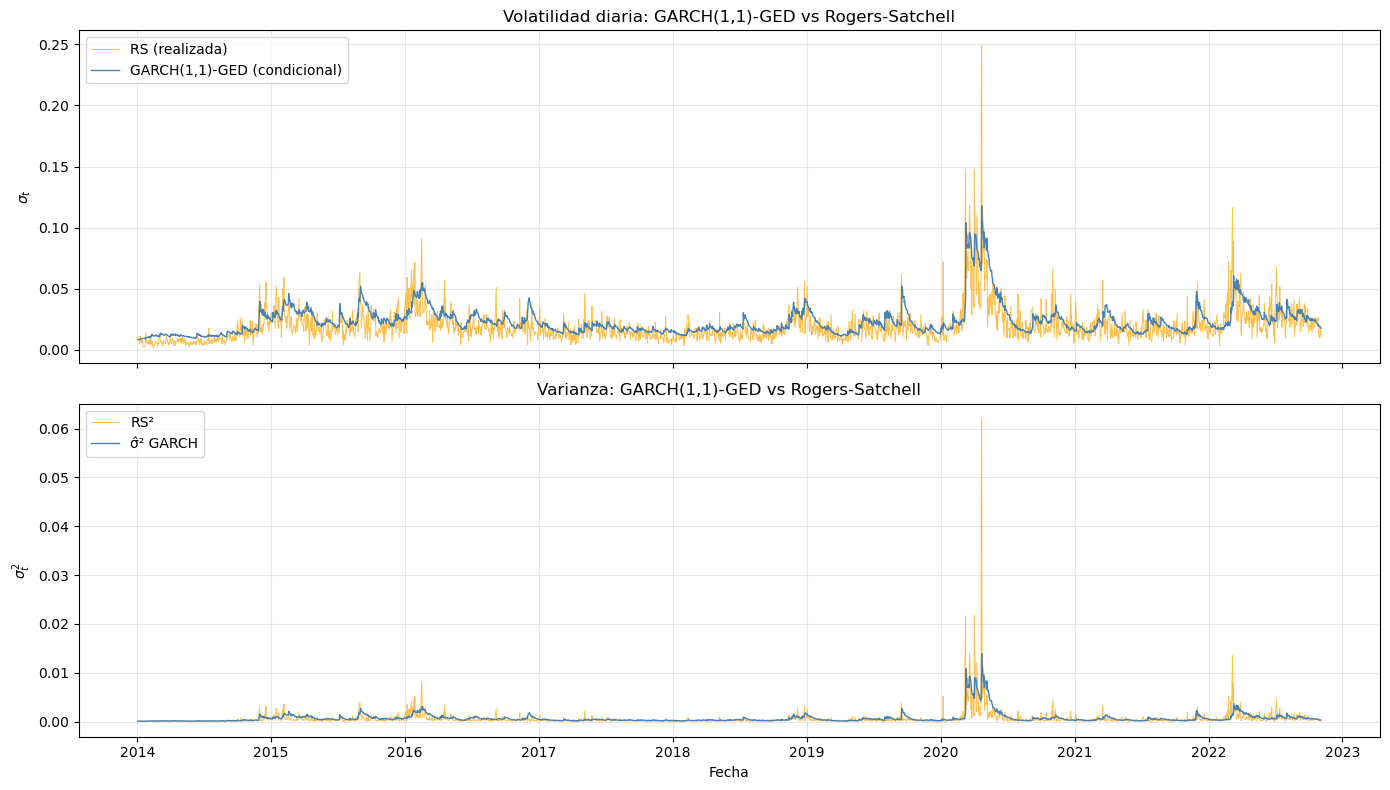

In [141]:
y  = df_train["log_returns"].values.astype("float64")
rs = df_train["rs_daily"].values.astype("float64")
idx = df_train.index


import matplotlib.pyplot as plt
sigma2_garch = res.conditional_volatility ** 2
sigma_garch  = np.sqrt(sigma2_garch)
sigma_rs     = np.sqrt(rs)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(idx, sigma_rs,    color="orange", lw=0.7, alpha=0.7, label="RS (realizada)")
axes[0].plot(idx, sigma_garch, color="steelblue", lw=1.0, label="GARCH(1,1)-GED (condicional)")
axes[0].set_ylabel(r"$\sigma_t$")
axes[0].set_title("Volatilidad diaria: GARCH(1,1)-GED vs Rogers-Satchell")
axes[0].legend(loc="upper left")
axes[0].grid(alpha=0.3)

axes[1].plot(idx, sigma_rs**2,    color="orange", lw=0.7, alpha=0.7, label="RS²")
axes[1].plot(idx, sigma2_garch,   color="steelblue", lw=1.0, label="σ̂² GARCH")
axes[1].set_ylabel(r"$\sigma_t^2$")
axes[1].set_xlabel("Fecha")
axes[1].set_title("Varianza: GARCH(1,1)-GED vs Rogers-Satchell")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.3)

plt.tight_layout()

In [144]:
# Calcular autocorrelación de r² y de RS en el training
from statsmodels.tsa.stattools import acf

r2 = y ** 2
acf_r2 = acf(r2, nlags=10)
acf_rs = acf(rs, nlags=10)

print("Lag | ACF(r²) | ACF(RS)")
for i in range(1, 11):
    print(f"  {i:2d} | {acf_r2[i]:+.4f} | {acf_rs[i]:+.4f}")

Lag | ACF(r²) | ACF(RS)
   1 | +0.2079 | +0.5715
   2 | +0.0723 | +0.2293
   3 | +0.0915 | +0.2068
   4 | +0.0894 | +0.2477
   5 | +0.1101 | +0.2525
   6 | +0.0944 | +0.1887
   7 | +0.1946 | +0.2171
   8 | +0.1368 | +0.2379
   9 | +0.0544 | +0.1996
  10 | +0.1524 | +0.1997


In [145]:
from arch import arch_model
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
for i, (train_idx, val_idx) in enumerate(tscv.split(y), 1):
    t0 = train_idx[-1] + 1
    res = arch_model(y[:t0], vol="GARCH", p=3, q=2, dist="ged", mean="Zero").fit(disp="off")
    b1 = res.params["beta[1]"]
    b2 = res.params["beta[2]"]
    print(f"Fold {i}: n={t0:4d}  beta[1]={b1:+.4f}  beta[2]={b2:+.4f}")

Fold 1: n= 366  beta[1]=+0.4230  beta[2]=+0.4230
Fold 2: n= 727  beta[1]=+0.3900  beta[2]=+0.3900
Fold 3: n=1088  beta[1]=+0.4400  beta[2]=+0.4400
Fold 4: n=1449  beta[1]=+0.3417  beta[2]=+0.5317
Fold 5: n=1810  beta[1]=+0.3024  beta[2]=+0.4882


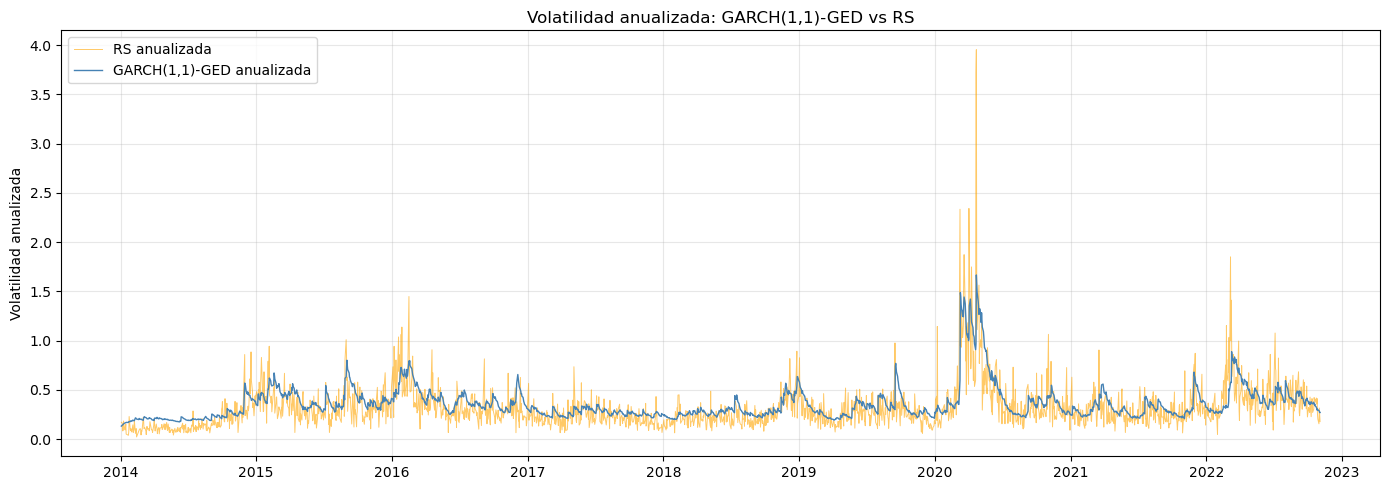

In [65]:
ann = np.sqrt(252)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(idx, sigma_rs * ann,    color="orange", lw=0.7, alpha=0.6, label="RS anualizada")
ax.plot(idx, sigma_garch * ann, color="steelblue", lw=1.0, label="GARCH(1,1)-GED anualizada")
ax.set_ylabel("Volatilidad anualizada")
ax.set_title("Volatilidad anualizada: GARCH(1,1)-GED vs RS")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
corr_levels = np.corrcoef(sigma_garch, sigma_rs)[0, 1]
corr_sq     = np.corrcoef(sigma2_garch, rs)[0, 1]

print(f"Correlación σ_GARCH vs σ_RS   = {corr_levels:.4f}")
print(f"Correlación σ²_GARCH vs RS    = {corr_sq:.4f}")

Correlación σ_GARCH vs σ_RS   = 0.6915
Correlación σ²_GARCH vs RS    = 0.5345


In [67]:
# Comparar RS vs r_t^2 para ver cuánto sobreestima RS
rs = df_train["rs_daily"].values
r2 = df_train["log_returns"].values ** 2

print(f"Media RS:  {rs.mean():.6f}")
print(f"Media r²:  {r2.mean():.6f}")
print(f"Ratio RS/r²: {rs.mean() / r2.mean():.3f}")

Media RS:  0.000617
Media r²:  0.000687
Ratio RS/r²: 0.898


## Modelo GJR-GARCH

El modelo GARCH impone una respuesta simétrica a los choques, de modo que una innovación positiva y una negativa de igual magnitud producen el mismo efecto sobre la varianza condicional. Esta limitación motivó la extensión propuesta por Glosten, Jagannathan y Runkle (1993), quienes incorporaron un término que permite que la varianza reaccione de forma diferencial según el signo de la innovación. El modelo resultante, conocido como GJR-GARCH, captura el efecto apalancamiento documentado en mercados de materias primas, donde los choques negativos tienden a aumentar la volatilidad más que los positivos.

La varianza condicional se puede modelar según el modelo GJR-GARCH de orden $p$ y $q$:

$$
\sigma_t^2 = \omega + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2 + \sum_{i=1}^{q} \gamma_i \mathbf{1}_{\{\varepsilon_{t-i}<0\}} \varepsilon_{t-i}^2 + \sum_{j=1}^{p} \beta_j \sigma_{t-j}^2,
$$

donde $\omega > 0$ captura el nivel basal de varianza, los coeficientes $\alpha_i \geq 0$ cuantifican la influencia de las innovaciones al cuadrado rezagadas, los coeficientes $\gamma_i \geq 0$ capturan la amplificación asimétrica cuando la innovación es negativa, y los coeficientes $\beta_j \geq 0$ reflejan la persistencia de la varianza condicional. El indicador $\mathbf{1}_{\{\varepsilon_{t-i}<0\}}$ toma el valor de uno cuando la innovación rezagada es negativa y cero en caso contrario, de modo que el término $\gamma_i \varepsilon_{t-i}^2$ solo se activa ante choques adversos. El modelo GARCH constituye un caso particular del GJR-GARCH cuando $\gamma_i = 0$ para todo $i$.

In [41]:
dists = ["normal", "t", "ged"]

optim_opts = {
    "maxiter": 10000,
    "ftol":    1e-6,
    "gtol":    1e-6,
}

grid_gjr = build_grid("GJR-GARCH", p_max=3, q_max=3)

df_ins = grid_search_insample(
    y, "GJR-GARCH", grid_gjr, dists,
    optim_opts=optim_opts,
    progress=True,
)

GJR-GARCH in-sample: 100%|██████████| 27/27 [00:01<00:00, 17.62it/s]


In [42]:
df_ins

,model,p,q,dist,loglik,k,AIC,BIC,HQIC
0,GJR-GARCH,1,1,normal,5251.921386,4,-10495.842771,-10473.110999,-10487.530750
1,GJR-GARCH,1,1,t,5357.678028,5,-10705.356057,-10676.941341,-10694.966030
2,GJR-GARCH,1,1,ged,5327.704172,5,-10645.408345,-10616.993629,-10635.018318
3,GJR-GARCH,1,2,normal,5249.011068,5,-10488.022136,-10459.607421,-10477.632110
4,GJR-GARCH,1,2,t,5356.403912,6,-10700.807824,-10666.710165,-10688.339792
5,GJR-GARCH,1,2,ged,5325.740440,6,-10639.480880,-10605.383221,-10627.012847
6,GJR-GARCH,1,3,normal,5255.370690,6,-10498.741380,-10464.643721,-10486.273348
7,GJR-GARCH,1,3,t,5356.951444,7,-10699.902889,-10660.122286,-10685.356851
8,GJR-GARCH,1,3,ged,5324.357115,7,-10634.714230,-10594.933628,-10620.168192
9,GJR-GARCH,2,1,normal,5254.842951,5,-10499.685901,-10471.271186,-10489.295874


In [43]:
df_pred = grid_search_predictive(
    y, rs, "GJR-GARCH", grid_gjr, dists,
    n_splits=5,
    metrics="all",
    optim_opts=optim_opts,
    progress=True,
)

best = select_best(df_pred, metric="qlike_mean", max_failed=2)
print(best)

GJR-GARCH TSCV: 100%|██████████| 27/27 [00:05<00:00,  4.72it/s]

model         GJR-GARCH
p                     1
q                     1
dist                ged
qlike_mean     0.367168
qlike_std      0.079357
mse_mean       0.000004
mse_std        0.000007
rmse_mean      0.001315
rmse_std       0.001481
mae_mean       0.000489
mae_std        0.000338
n_failed              0
Name: 2, dtype: object


In [44]:
df_pred

,model,p,q,dist,qlike_mean,qlike_std,mse_mean,mse_std,rmse_mean,rmse_std,mae_mean,mae_std,n_failed
0,GJR-GARCH,1,1,normal,0.377678,0.076738,0.000004,0.000007,0.001325,0.001477,0.000490,0.000313,0
1,GJR-GARCH,1,1,t,0.373025,0.080628,0.000004,0.000007,0.001316,0.001480,0.000474,0.000303,0
2,GJR-GARCH,1,1,ged,0.367168,0.079357,0.000004,0.000007,0.001315,0.001481,0.000489,0.000338,0
3,GJR-GARCH,1,2,normal,0.377574,0.080374,0.000004,0.000007,0.001332,0.001481,0.000501,0.000336,0
4,GJR-GARCH,1,2,t,0.402621,0.116593,0.000004,0.000007,0.001337,0.001482,0.000503,0.000337,0
5,GJR-GARCH,1,2,ged,0.400423,0.118879,0.000004,0.000007,0.001335,0.001483,0.000501,0.000339,0
6,GJR-GARCH,1,3,normal,0.392477,0.098957,0.000004,0.000007,0.001333,0.001484,0.000505,0.000338,0
7,GJR-GARCH,1,3,t,0.403028,0.119818,0.000004,0.000007,0.001338,0.001483,0.000495,0.000325,0
8,GJR-GARCH,1,3,ged,0.402086,0.119585,0.000004,0.000007,0.001338,0.001484,0.000502,0.000339,0
9,GJR-GARCH,2,1,normal,0.380844,0.091576,0.000004,0.000007,0.001295,0.001439,0.000495,0.000341,0


## Modelo EGARCH

El modelo GJR-GARCH captura la asimetría mediante un umbral explícito que activa un término adicional cuando la innovación es negativa. Una aproximación alternativa fue propuesta por Nelson (1991), quien especificó la varianza condicional en forma logarítmica, dando lugar al modelo Exponencial GARCH (EGARCH). Esta formulación modela directamente el logaritmo de la varianza, lo que introduce dos ventajas estructurales: garantiza la positividad de $\sigma_t^2$ sin necesidad de restricciones sobre los parámetros, y captura la asimetría de forma multiplicativa en lugar de aditiva.

La varianza condicional se puede modelar según el modelo EGARCH de orden $p$ y $q$:

$$
\ln(\sigma_t^2) = \omega + \sum_{j=1}^{p} \beta_j \ln(\sigma_{t-j}^2) + \sum_{i=1}^{q} \alpha_i \left( |z_{t-i}| - E|z_{t-i}| \right) + \sum_{i=1}^{q} \gamma_i z_{t-i},
$$

donde $\omega$ captura el nivel basal de log-varianza, los coeficientes $\beta_j$ describen la persistencia en la varianza transformada, los coeficientes $\alpha_i$ regulan la reacción de magnitud ante los residuos estandarizados y los coeficientes $\gamma_i$ caracterizan el ajuste asimétrico asociado al signo de la innovación. Los residuos estandarizados $z_{t-i} = \varepsilon_{t-i} / \sigma_{t-i}$ se normalizan por la volatilidad rezagada para garantizar invarianza de escala en su efecto. El término $E|z_{t-i}|$ es la esperanza del valor absoluto de $z_t$ bajo la distribución asumida, que actúa como constante de centrado.

In [118]:
dists = ["normal", "t", "ged"]

optim_opts = {
    "maxiter": 500,
    "ftol":    1e-6,
    "gtol":    1e-6,
}

grid_egarch = build_grid("EGARCH", p_max=3, q_max=3)

df_ins_egarch = grid_search_insample(
    y, "EGARCH", grid_egarch, dists,
    optim_opts=optim_opts,
    progress=True,
)

EGARCH in-sample: 100%|██████████| 27/27 [00:03<00:00,  8.69it/s]


In [115]:
df_ins_egarch 

,model,p,q,dist,loglik,k,AIC,BIC,HQIC
0,EGARCH,1,1,normal,5271.031292,4,-10534.062584,-10511.330811,-10525.750563
1,EGARCH,1,1,t,5371.897513,5,-10733.795026,-10705.380310,-10723.404999
2,EGARCH,1,1,ged,5354.734074,5,-10699.468147,-10671.053431,-10689.078120
3,EGARCH,1,2,normal,5271.846954,5,-10533.693908,-10505.279193,-10523.303881
4,EGARCH,1,2,t,5372.133937,6,-10732.267873,-10698.170214,-10719.799841
5,EGARCH,1,2,ged,5355.187170,6,-10698.374340,-10664.276681,-10685.906307
6,EGARCH,1,3,normal,5271.876379,6,-10531.752758,-10497.655099,-10519.284726
7,EGARCH,1,3,t,5372.392720,7,-10730.785439,-10691.004837,-10716.239401
8,EGARCH,1,3,ged,5355.333707,7,-10696.667413,-10656.886811,-10682.121375
9,EGARCH,2,1,normal,5271.327601,5,-10532.655201,-10504.240485,-10522.265174


In [122]:
df_egarch = grid_search_predictive(
    y, rs, "EGARCH", grid_egarch, dists,
    h=1, n_splits=5, metrics="all",
    optim_opts=optim_opts, progress=True,
)

tabla_num = format_table(
    df_egarch,
    aggregate="robust",
    metrics=("qlike", "rmse"),
    sort_by="qlike",
    include_exploded=True,
)

EGARCH TSCV h=1: 100%|██████████| 27/27 [00:37<00:00,  1.41s/it]

=== Tabla numérica (robust) ===
     model  p  q    dist  qlike_center  qlike_spread  rmse_center  rmse_spread  qlike_n  n_failed  qlike_n_exploded
1   EGARCH  2  2  normal         0.658         0.386        0.001        0.001        5         0                 0
2   EGARCH  3  2  normal         0.660         0.387        0.001        0.001        5         0                 0
3   EGARCH  2  3     ged         0.665         0.104        0.001        0.001        5         0                 0
4   EGARCH  2  1     ged         0.691         0.519        0.001        0.001        5         0                 0
5   EGARCH  3  1       t         0.692         0.425        0.001        0.001        5         0                 0
6   EGARCH  2  1  normal         0.692         0.579        0.001        0.000        5         0                 0
7   EGARCH  3  1  normal         0.694         0.423        0.001        0.000        5         0                 0
8   EGARCH  1  2  normal         0.711  

In [129]:
print("\n=== Tabla display (±) ===")
print(display_table(tabla_num.head(10)).to_string())


=== Tabla display (±) ===
     model  p  q    dist            QLIKE                 RMSE  qlike_n  n_failed  qlike_n_exploded
1   EGARCH  2  2  normal  0.6584 ± 0.3857  0.000781 ± 0.000607        5         0                 0
2   EGARCH  3  2  normal  0.6597 ± 0.3865  0.000843 ± 0.000608        5         0                 0
3   EGARCH  2  3     ged  0.6649 ± 0.1044  0.000734 ± 0.000655        5         0                 0
4   EGARCH  2  1     ged  0.6912 ± 0.5188  0.000812 ± 0.000532        5         0                 0
5   EGARCH  3  1       t  0.6917 ± 0.4248  0.001100 ± 0.000891        5         0                 0
6   EGARCH  2  1  normal  0.6919 ± 0.5785  0.000781 ± 0.000491        5         0                 0
7   EGARCH  3  1  normal  0.6937 ± 0.4233  0.000791 ± 0.000492        5         0                 0
8   EGARCH  1  2  normal  0.7111 ± 0.3591  0.001017 ± 0.000670        5         0                 0
9   EGARCH  2  2       t  0.7114 ± 0.0956  0.000903 ± 0.000665        5  

In [130]:
p_best, q_best, dist_best = 2, 3, "ged"

model = arch_model(y, vol="EGARCH", p=p_best, q=q_best, o=1,
                   dist=dist_best, mean="Zero")
res = model.fit(disp="off")

print(res.summary())

                             Zero Mean - EGARCH Model Results                             
Dep. Variable:                                  y   R-squared:                       0.000
Mean Model:                             Zero Mean   Adj. R-squared:                  0.000
Vol Model:                                 EGARCH   Log-Likelihood:                5355.19
Distribution:      Generalized Error Distribution   AIC:                          -10694.4
Method:                        Maximum Likelihood   BIC:                          -10648.9
                                                    No. Observations:                 2171
Date:                            Mon, Sep 28 2026   Df Residuals:                     2171
Time:                                    18:47:29   Df Model:                            0
                              Volatility Model                             
                 coef    std err          t      P>|t|     95.0% Conf. Int.
-----------------------------

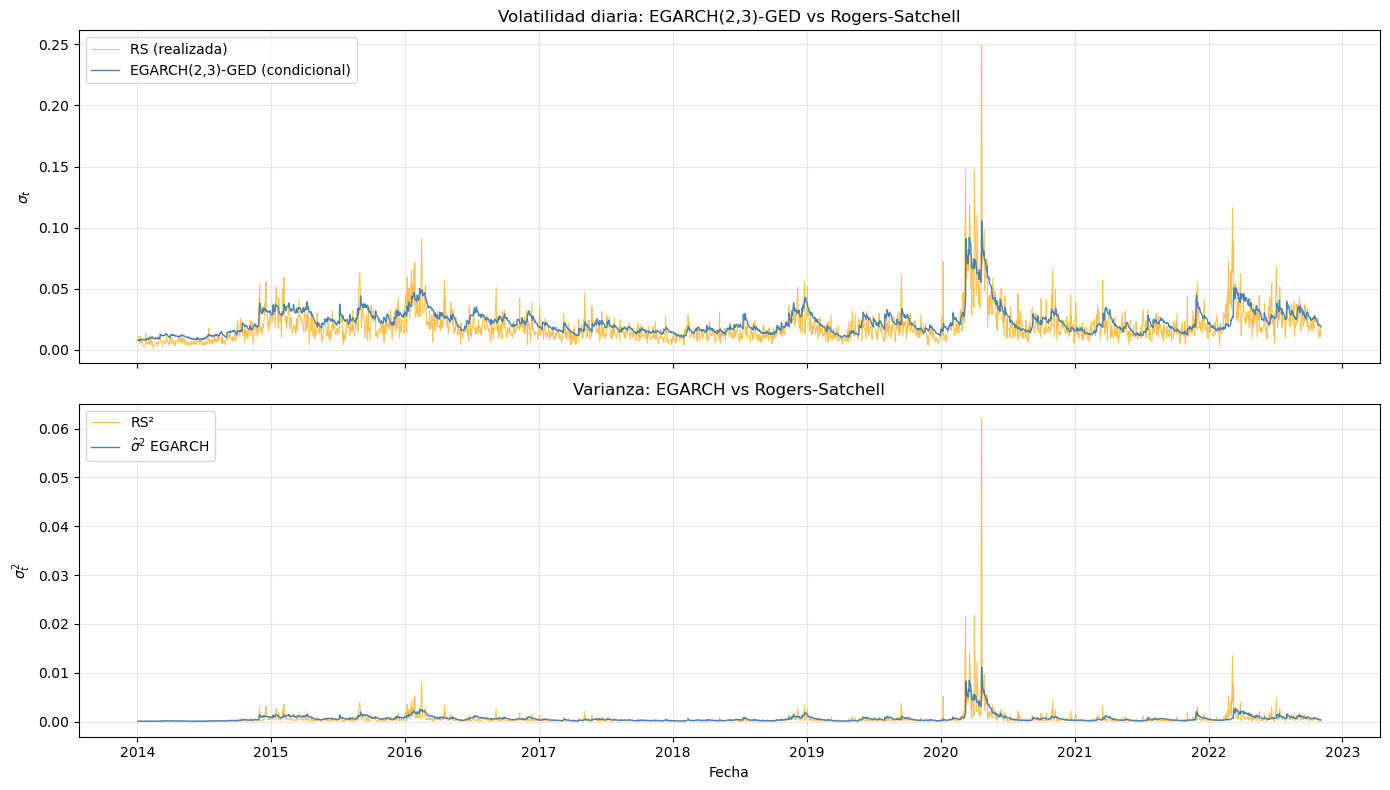

In [131]:
sigma_egarch = res.conditional_volatility
sigma_rs     = np.sqrt(rs)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(idx, sigma_rs,     color="orange",    lw=0.7, alpha=0.7, label="RS (realizada)")
axes[0].plot(idx, sigma_egarch, color="steelblue", lw=1.0, label=f"EGARCH({p_best},{q_best})-{dist_best.upper()} (condicional)")
axes[0].set_ylabel(r"$\sigma_t$")
axes[0].set_title(f"Volatilidad diaria: EGARCH({p_best},{q_best})-{dist_best.upper()} vs Rogers-Satchell")
axes[0].legend(loc="upper left")
axes[0].grid(alpha=0.3)

axes[1].plot(idx, sigma_rs**2,     color="orange",    lw=0.7, alpha=0.7, label="RS²")
axes[1].plot(idx, sigma_egarch**2, color="steelblue", lw=1.0, label=r"$\hat{\sigma}^2$ EGARCH")
axes[1].set_ylabel(r"$\sigma_t^2$")
axes[1].set_xlabel("Fecha")
axes[1].set_title("Varianza: EGARCH vs Rogers-Satchell")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()